# 05 · The two-spin search at L = 11

This repeats the L = 9 search (notebooks 03–04) at $L = 11$ with 5-spin blocks ($l = 4$). The Hilbert space has dimension 2048, and one evaluation of $\Phi$ costs roughly 50 times more than at $L = 9$. Both searches are therefore warm-started from the L = 9 optima:

* **Min 1 (Newton):** L-BFGS-B over all six parameters, seeded at the L = 9 Min 1.
* **Min 2 (DE):** differential evolution over the couplings with $J = J_\mathrm{PRX}$. The population of 25 holds the L = 9 Min 2, 12 tight perturbations ($\sigma = 0.2$) and 12 loose ones ($\sigma = 1$). It runs 20 generations instead of 200.

Each optimum is rotated to the standard frame and checked with the reduced $5 \times 5$ Hessian ($c_{YZ+ZY}$ pinned at 0) and a $9 \times 9$ plane scan along its two softest modes.

The searches run in `scripts/run_L11_search.py` (1.5–3 h), which writes `results/L11_search.json`. This notebook only loads and plots that file.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from spin_eth import PARAMS, CanonicalModel
from spin_eth.analysis import describe_modes
from spin_eth.constants import R_GOE, R_GUE, R_POISSON
from spin_eth.io import load_json
from spin_eth.plotting import plot_mode_scan

RESULTS, FIGURES = Path("../results"), Path("../figures")
search = load_json(RESULTS / "L11_search.json")
stored = load_json(RESULTS / "minima.json")
phi_prx = search["phi_prx"]
mins = {"Min 1 (Newton)": search["min1"], "Min 2 (DE)": search["min2"]}

## 1. Results

In [2]:
print(f"L=11, l=4, middle 50% of the spectrum.  Phi(PRX) = {phi_prx:.6e}\n")
for name, m in mins.items():
    print(f"{name}: optimizer Phi = {m['optimizer_fun']:.6e} (success={m['optimizer_success']}, {m['optimizer_nfev']} evaluations)")
    print(f"  {m['n_neg']} negative eigenvalues in the reduced Hessian")

table = pd.DataFrame({name: {"Phi": m["phi"], "vs PRX": phi_prx / m["phi"], **dict(zip(PARAMS, m["x_std"]))}
                      for name, m in mins.items()}).T
print("\nStandard frame:")
print(table.to_string(formatters={"Phi": "{:.6e}".format, "vs PRX": "{:.4f}x".format,
                                  **{p: "{:+.4f}".format for p in PARAMS}}))
for name, key in (("Min 1 (Newton)", "min1_standard"), ("Min 2 (DE)", "min2_standard")):
    diff = np.max(np.abs(np.array(mins[name]["x_std"]) - stored["L11"][key]))
    print(f"{name}: max |difference| from results/minima.json = {diff:.1e}  (stored to 6 significant figures)")

model9 = CanonicalModel(9, 3)
phi9 = {"PRX": model9.phi_mfim(),
        "Min 1 (Newton)": model9.phi(stored["L9"]["min1_canonical"]),
        "Min 2 (DE)": model9.phi(stored["L9"]["min2_canonical"])}
print("\nImprovement over PRX by system size (absolute Phi depends on (L, l), so compare ratios):")
print(f"  {'':>16}  {'L=9 (l=3)':>10}  {'L=11 (l=4)':>10}")
for name in mins:
    print(f"  {name:>16}  {phi9['PRX'] / phi9[name]:9.4f}x  {phi_prx / mins[name]['phi']:9.4f}x")

L=11, l=4, middle 50% of the spectrum.  Phi(PRX) = 4.553219e-02

Min 1 (Newton): optimizer Phi = 3.677807e-02 (success=True, 210 evaluations)
  0 negative eigenvalues in the reduced Hessian
Min 2 (DE): optimizer Phi = 3.634512e-02 (success=False, 639 evaluations)
  0 negative eigenvalues in the reduced Hessian

Standard frame:
                        Phi  vs PRX       J      XX      YY   XY+YX   XZ+ZX   YZ+ZY
Min 1 (Newton) 3.677807e-02 1.2380x +0.0723 +0.5607 +0.7317 -0.4501 +0.3628 -0.0000
Min 2 (DE)     3.634512e-02 1.2528x +0.0639 +0.4826 +1.3899 -0.2143 +0.8783 -0.0000
Min 1 (Newton): max |difference| from results/minima.json = 4.4e-07  (stored to 6 significant figures)
Min 2 (DE): max |difference| from results/minima.json = 9.2e-07  (stored to 6 significant figures)



Improvement over PRX by system size (absolute Phi depends on (L, l), so compare ratios):
                     L=9 (l=3)  L=11 (l=4)
    Min 1 (Newton)     1.3717x     1.2380x
        Min 2 (DE)     1.3958x     1.2528x


## 2. Curvature and plane scans

The reduced Hessian eigenvalues are about 7–10 times smaller than at $L = 9$. Both optima are much shallower minima.

      Min 1 (Newton)  Min 2 (DE)
mode                            
1        +1.0483e-01 +8.2653e-02
2        +1.2156e-01 +1.2709e-01
3        +1.4596e-01 +1.2858e-01
4        +1.8779e-01 +1.5171e-01
5        +2.5388e-01 +1.6821e-01

Min 1 (Newton):
    mode 1: +1.0483e-01  [pos]  XY+YX(-0.81), J(+0.53)
    mode 2: +1.2156e-01  [pos]  YY(-0.83), XX(+0.34)
    mode 3: +1.4596e-01  [pos]  XZ+ZX(-0.82), J(+0.50)
    mode 4: +1.8779e-01  [pos]  J(+0.67), XY+YX(+0.44)
    mode 5: +2.5388e-01  [pos]  XX(+0.93), YY(+0.25)

Min 2 (DE):
    mode 1: +8.2653e-02  [pos]  XX(-0.93), J(+0.28)
    mode 2: +1.2709e-01  [pos]  XZ+ZX(+0.55), YY(+0.47)
    mode 3: +1.2858e-01  [pos]  J(+0.67), XZ+ZX(-0.53)
    mode 4: +1.5171e-01  [pos]  YY(-0.76), XZ+ZX(+0.64)
    mode 5: +1.6821e-01  [pos]  XY+YX(+0.85), J(+0.48)


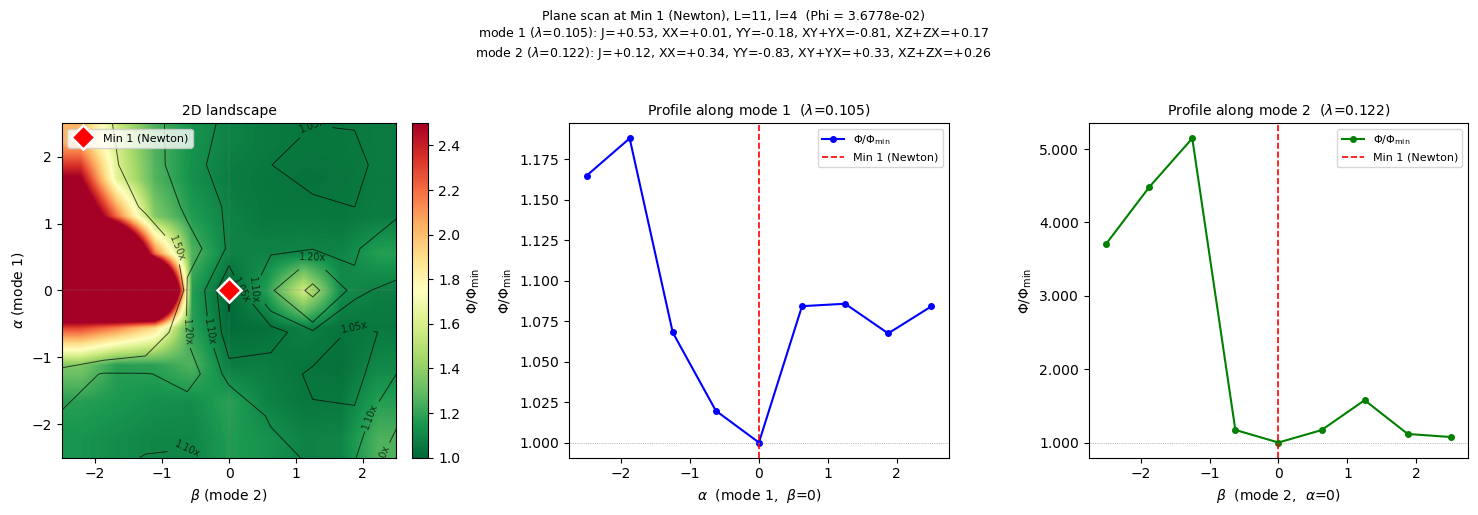

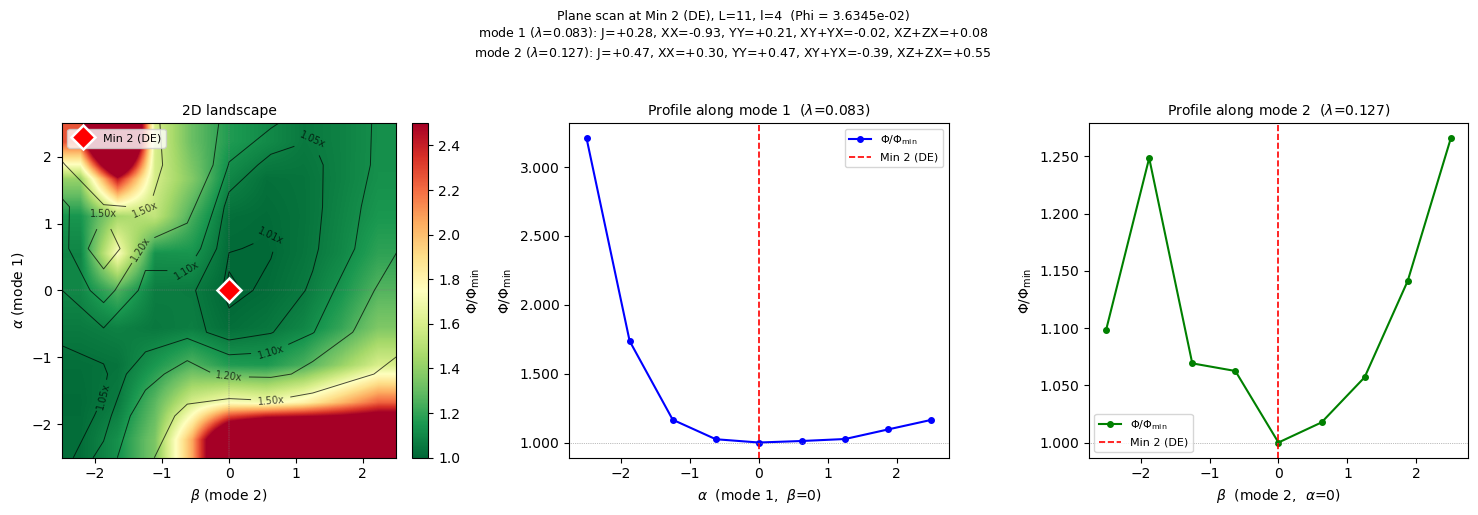

In [3]:
evals = pd.DataFrame({name: m["evals"] for name, m in mins.items()}, index=pd.RangeIndex(1, 6, name="mode"))
print(evals.to_string(float_format="{:+.4e}".format))
for name, m in mins.items():
    print(f"\n{name}:")
    print(describe_modes(np.array(m["evals"]), np.array(m["evecs"]), PARAMS[:5]))

FIGURES.mkdir(exist_ok=True)
for i, (name, m) in enumerate(mins.items(), start=1):
    alphas, grid = np.array(m["alphas"]), np.array(m["grid"])
    plot_mode_scan(grid, alphas, alphas, np.array(m["evals"]), np.array(m["evecs"]), PARAMS[:5], m["phi"],
                   title=f"Plane scan at {name}, L=11, l=4  (Phi = {m['phi']:.4e})", center_label=name,
                   savepath=FIGURES / f"L11_min{i}_plane_scan.png");

## 3. Level-spacing ratio ⟨r⟩

The same statistic as notebook 04 §5, now with 1022 ratios, at the stored standard-frame optima.

In [4]:
model11 = CanonicalModel(11, 4)
points = {"PRX (g=1.08, h=0.30)": None,
          "Min 1 (Newton)": stored["L11"]["min1_standard"],
          "Min 2 (DE)": stored["L11"]["min2_standard"]}
r11 = {k: model11.level_spacing_ratio(model11.mfim_hamiltonian() if x is None else model11.hamiltonian(np.array(x)))
       for k, x in points.items()}
r9 = {"PRX (g=1.08, h=0.30)": model9.level_spacing_ratio(model9.mfim_hamiltonian()),
      "Min 1 (Newton)": model9.level_spacing_ratio(model9.hamiltonian(np.array(stored["L9"]["min1_canonical"]))),
      "Min 2 (DE)": model9.level_spacing_ratio(model9.hamiltonian(np.array(stored["L9"]["min2_canonical"])))}

table = pd.DataFrame({k: {"<r>": r, "std": s, "vs GOE": r - R_GOE, "vs GUE": r - R_GUE, "<r> at L=9": r9[k][0]}
                      for k, (r, s, _) in r11.items()}).T
n = next(iter(r11.values()))[2]
print(f"<r> over the middle 50% of the spectrum (L=11, {n} ratios)")
print(table.to_string(formatters={c: ("{:+.4f}" if c.startswith("vs") else "{:.4f}").format for c in table.columns}))
std_prx = r11["PRX (g=1.08, h=0.30)"][1]
print(f"\nReference: Poisson {R_POISSON}, GOE {R_GOE}, GUE {R_GUE};  standard error ~ std/sqrt(N) = {std_prx / np.sqrt(n):.4f}")
r = {k: v[0] for k, v in r11.items()}
names = list(r)
print(f"PRX -> Min 1: {r[names[1]] - r[names[0]]:+.4f}   PRX -> Min 2: {r[names[2]] - r[names[0]]:+.4f}   "
      f"Min 1 -> Min 2: {r[names[2]] - r[names[1]]:+.4f}")

<r> over the middle 50% of the spectrum (L=11, 1022 ratios)
                        <r>    std  vs GOE  vs GUE <r> at L=9
PRX (g=1.08, h=0.30) 0.5570 0.2489 +0.0263 -0.0426     0.5434
Min 1 (Newton)       0.5936 0.2351 +0.0629 -0.0060     0.5683
Min 2 (DE)           0.6044 0.2332 +0.0737 +0.0048     0.5787

Reference: Poisson 0.3863, GOE 0.5307, GUE 0.5996;  standard error ~ std/sqrt(N) = 0.0078
PRX -> Min 1: +0.0366   PRX -> Min 2: +0.0475   Min 1 -> Min 2: +0.0108
